# Three distinct data mining methods and evaluations

**Project:** Mining EV Registration Patterns in Washington State  
**Authors:** Afsana Tasnim Juha, Mamata Joshi, Prasanna Thapa


# 1.Apriori association rule mining

**Research question.** Which combinations of vehicle attributes occur more frequently than expected by chance?

We examine manufacturer, EV type, and five-year model-year group in the sampled Washington EV registrations. Each row represents one vehicle registration. We compare observed co-occurrence with the co-occurrence expected under independence using **lift**.

## 1.1 Load the vehicle transactions

Each registration contributes one item from each of three fields. Field names prefix the values so that every item has a clear meaning. The vehicle ID is used only to check that each registration appears once.

In [36]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

filename = "association_transactions.csv"
folders = (Path("."), Path("data/processed/week09"), Path("upload"))
source = next((folder / filename for folder in folders if (folder / filename).is_file()), None)
if source is None:
    raise FileNotFoundError(f"Place {filename} beside this notebook or in a project data folder.")

attributes = ["Make", "EV_Type", "Year_Group"]
vehicles = pd.read_csv(source, dtype="string", usecols=["DOL Vehicle ID", *attributes])
assert not vehicles.empty
assert not vehicles.isna().any().any()
assert vehicles["DOL Vehicle ID"].is_unique

items = pd.get_dummies(vehicles[attributes], prefix_sep="=", dtype=bool)
assert items.sum(axis=1).eq(len(attributes)).all()
n = len(vehicles)
print(f"Registrations: {n:,}")
print(f"Distinct items: {items.shape[1]}")
print(vehicles[attributes].nunique().to_string())
print("\nEV type counts")
print(vehicles["EV_Type"].value_counts().to_string())

Registrations: 49,873
Distinct items: 56
Make          47
EV_Type        2
Year_Group     7

EV type counts
EV_Type
BEV     40168
PHEV     9705


## 1.2 Find frequent itemsets with Apriori

The methods plan sets a minimum support of **1%** and a maximum of **three items**. Apriori first counts single items and then tests pairs and triples. A candidate can reach the support threshold only if each of its smaller subsets also reaches it. We use this property to skip candidates before counting them.

In [37]:
min_support = 0.01
min_confidence = 0.60
max_length = 3

masks = {column: items[column].to_numpy() for column in sorted(items)}
frequent = {}
previous_level = set()

for length in range(1, max_length + 1):
    current_level = set()
    for candidate in combinations(masks, length):
        if length > 1 and any(
            subset not in previous_level for subset in combinations(candidate, length - 1)
        ):
            continue
        count = int(np.logical_and.reduce([masks[item] for item in candidate]).sum())
        if count / n >= min_support:
            frequent[candidate] = count
            current_level.add(candidate)
    print(f"{length}-item sets meeting minimum support: {len(current_level)}")
    previous_level = current_level

1-item sets meeting minimum support: 23
2-item sets meeting minimum support: 52
3-item sets meeting minimum support: 19


## 1.3 Build and evaluate association rules

A rule has a left side, **A**, and a right side, **B**. We report the number of registrations containing both sides along with three measures.

| Measure | Calculation | Meaning |
|---|---|---|
| Support | Count containing both sides ÷ total registrations | How common the full combination is |
| Confidence | Count containing both sides ÷ count containing A | How often B occurs when A occurs |
| Lift | Confidence ÷ overall proportion containing B | How much more often B occurs with A than expected under independence |

We keep rules with confidence of **at least 60%** and lift **above 1**. We also show the expected count under independence. A rule and its reverse have the same support and lift, while confidence can differ. The chart uses one direction per pair of sides to avoid displaying the same association twice.

In [38]:
records = []
for itemset, observed in frequent.items():
    for size in range(1, len(itemset)):
        for left in combinations(itemset, size):
            right = tuple(item for item in itemset if item not in left)
            left_count, right_count = frequent[left], frequent[right]
            confidence = observed / left_count
            expected = left_count * right_count / n
            lift = observed / expected
            if confidence >= min_confidence and lift > 1:
                records.append({
                    "antecedent": " + ".join(left),
                    "consequent": " + ".join(right),
                    "observed": observed,
                    "expected": expected,
                    "support": observed / n,
                    "confidence": confidence,
                    "lift": lift,
                    "association": tuple(sorted((left, right))),
                })

rules = pd.DataFrame(records).sort_values(
    ["lift", "observed", "confidence", "antecedent", "consequent"],
    ascending=[False, False, False, True, True],
).reset_index(drop=True)
assert rules["support"].ge(min_support).all()
assert rules["confidence"].ge(min_confidence).all()
assert rules["observed"].gt(rules["expected"]).all()

distinct_rules = rules.drop_duplicates("association")
print(f"Qualifying directional rules: {len(rules)}")
print(f"Associations after combining reverse directions: {len(distinct_rules)}")
print(rules.drop(columns="association").head(12).to_string(
    index=False,
    formatters={"expected": "{:.1f}".format, "support": "{:.2%}".format,
                "confidence": "{:.2%}".format, "lift": "{:.3f}".format},
))

Qualifying directional rules: 45
Associations after combining reverse directions: 45
                        antecedent                          consequent  observed expected support confidence   lift
EV_Type=BEV + Year_Group=2010-2014                         Make=NISSAN       527     45.6   1.06%     62.89% 11.552
                         Make=JEEP EV_Type=PHEV + Year_Group=2020-2024       935    102.7   1.87%     89.73%  9.101
                     Make=CHRYSLER                        EV_Type=PHEV       612    119.1   1.23%    100.00%  5.139
  Make=JEEP + Year_Group=2020-2024                        EV_Type=PHEV       935    184.5   1.87%     98.63%  5.068
                         Make=JEEP                        EV_Type=PHEV      1002    202.8   2.01%     96.16%  4.942
Make=TOYOTA + Year_Group=2020-2024                        EV_Type=PHEV       865    211.5   1.73%     79.58%  4.089
                       Make=TOYOTA                        EV_Type=PHEV      1767    444.8   3.54%     7

## 1.4 Compare the strongest associations

The dashed line shows lift of 1, the value expected under independence. Read the chart alongside the support and observed counts in the table. A high lift can come from a relatively small group.

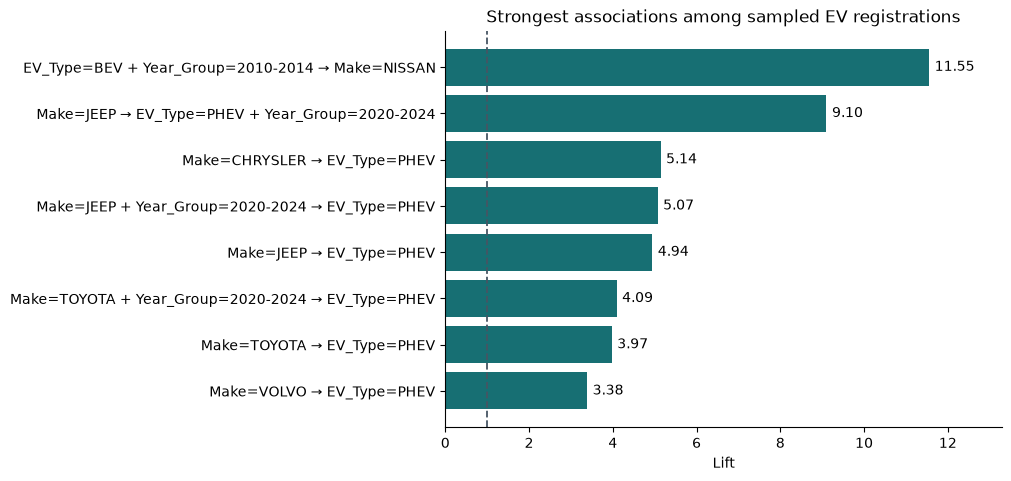

In [39]:
plot_data = distinct_rules.head(8).iloc[::-1]
labels = plot_data["antecedent"] + " → " + plot_data["consequent"]

fig, ax = plt.subplots(figsize=(10, 4.7), layout="constrained")
bars = ax.barh(labels, plot_data["lift"], color="#176f73")
ax.axvline(1, color="#465563", linestyle="--", linewidth=1.3)
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set(xlabel="Lift", title="Strongest associations among sampled EV registrations",
       xlim=(0, plot_data["lift"].max() * 1.15))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 1.5 Findings and limitations

- **Highest lift.** For `EV_Type=BEV + Year_Group=2010-2014 → Make=NISSAN`, 527 registrations matched both sides, compared with 45.6 expected under independence. The lift was 11.55. The rule covered 1.06% of the sample, and 62.9% of registrations on the left side also matched the right side.
- **Highest support among retained rules.** For `Year_Group=2020-2024 → EV_Type=BEV`, 24,095 registrations matched both sides (48.31% of the sample). Confidence was 83.1% and lift was 1.03. This shows how a widely occurring combination can have a smaller lift than the highest-ranked rule.

These associations describe the sampled registrations. Lift compares observed frequency with an independence benchmark. We did not run significance tests or assess generalization beyond this sample. The minimum support can exclude patterns involving rare manufacturers or older model-year groups. Five-year groups can also hide differences between individual model years.



#  2 .K-means clustering of ZIP code fleet profiles

In [40]:


scaled = pd.read_csv("data/processed/week09/zip_clustering_scaled.csv", dtype={"Postal Code": "string"})
profiles = pd.read_csv("data/processed/week09/zip_clustering_profiles.csv", dtype={"Postal Code": "string"})

features = ["Log_EV_Count", "BEV_Percentage", "Avg_Model_Year"]

print("Scaled table:", scaled.shape, "| Profiles table:", profiles.shape)
print("Same ZIP codes in both:", set(scaled["Postal Code"]) == set(profiles["Postal Code"]))
print("Missing values in features:", int(scaled[features].isna().sum().sum()))
print(scaled[features].describe().round(2))

Scaled table: (249, 4) | Profiles table: (249, 11)
Same ZIP codes in both: True
Missing values in features: 0
       Log_EV_Count  BEV_Percentage  Avg_Model_Year
count        249.00          249.00          249.00
mean           0.00            0.00            0.00
std            1.00            1.00            1.00
min           -1.87           -5.74           -2.81
25%           -0.83           -0.51           -0.55
50%           -0.02            0.06            0.04
75%            0.73            0.70            0.60
max            2.68            2.86            3.92


 k  inertia  silhouette  smallest_cluster  largest_cluster
 2    509.8       0.287               106              143
 3    408.9       0.282                67               99
 4    341.9       0.272                52               81
 5    279.4       0.296                24               87
 6    249.0       0.300                 2               86


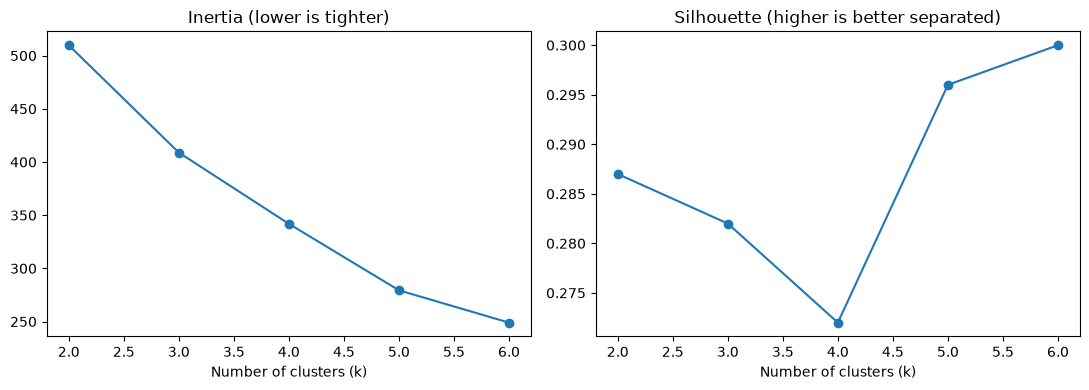

In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = scaled[features].values

rows = []
models = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X)
    models[k] = (km, labels)
    sizes = np.bincount(labels)
    rows.append({
        "k": k,
        "inertia": round(km.inertia_, 1),
        "silhouette": round(silhouette_score(X, labels), 3),
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(results["k"], results["inertia"], marker="o")
ax[0].set_title("Inertia (lower is tighter)")
ax[0].set_xlabel("Number of clusters (k)")
ax[1].plot(results["k"], results["silhouette"], marker="o")
ax[1].set_title("Silhouette (higher is better separated)")
ax[1].set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()

In [42]:
prof = profiles.set_index("Postal Code").loc[scaled["Postal Code"]].reset_index()

def describe(k):
    labels = models[k][1]
    tmp = prof.assign(cluster=labels)
    return tmp.groupby("cluster").agg(
        ZIP_codes=("Postal Code", "count"),
        Median_vehicles=("EV_Count", "median"),
        Avg_BEV_pct=("BEV_Percentage", "mean"),
        Avg_model_year=("Avg_Model_Year", "mean"),
    ).round(1)

for k in (2, 5):
    print("k =", k)
    print(describe(k))
    print()

labels6 = models[6][1]
tiny = int(np.bincount(labels6).argmin())
print("k = 6, smallest cluster:")
print(prof.assign(cluster=labels6).query("cluster == @tiny")[["Postal Code", "EV_Count", "BEV_Percentage", "Avg_Model_Year"]])

k = 2
         ZIP_codes  Median_vehicles  Avg_BEV_pct  Avg_model_year
cluster                                                         
0              143             89.0         75.6          2022.0
1              106            267.0         83.1          2022.5

k = 5
         ZIP_codes  Median_vehicles  Avg_BEV_pct  Avg_model_year
cluster                                                         
0               39             71.0         76.2          2021.4
1               87            189.0         77.7          2022.2
2               46             58.0         82.5          2022.5
3               24             74.5         65.8          2022.3
4               53            339.0         85.4          2022.7

k = 6, smallest cluster:
   Postal Code  EV_Count  BEV_Percentage  Avg_Model_Year
39       98057       162       39.506173     2023.561728
80       98188       308       55.519481     2023.133117


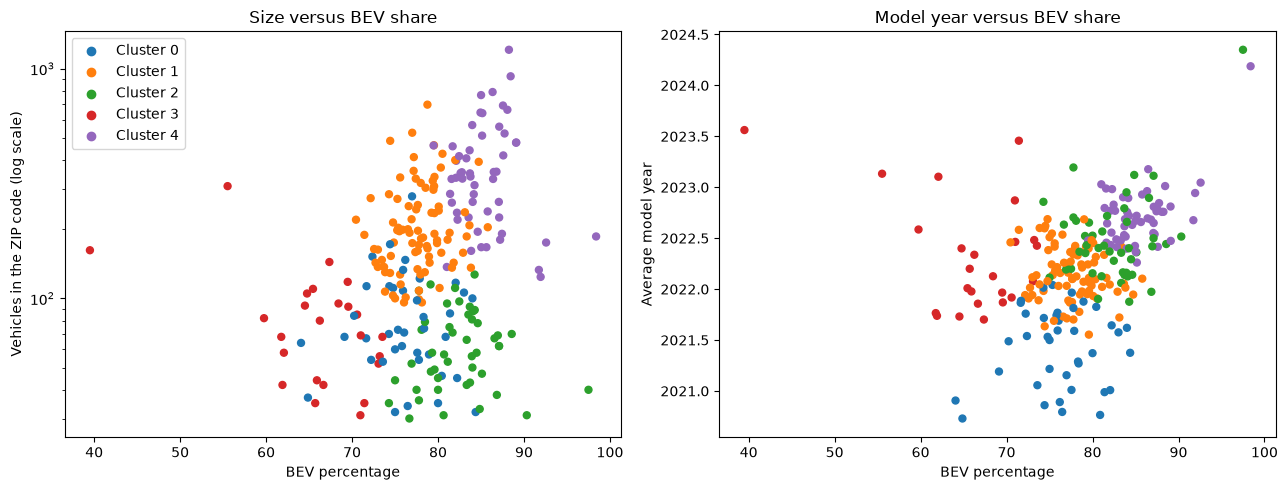

Saved 249 ZIP codes to data\processed\mining\zip_clusters_k5.csv


In [43]:
from pathlib import Path

K = 5
labels = models[K][1]
final = prof.assign(cluster=labels)
colors = [plt.cm.tab10(c) for c in labels]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(final["BEV_Percentage"], final["EV_Count"], color=colors, s=25)
ax[0].set_yscale("log")
ax[0].set_xlabel("BEV percentage")
ax[0].set_ylabel("Vehicles in the ZIP code (log scale)")
ax[0].set_title("Size versus BEV share")
ax[1].scatter(final["BEV_Percentage"], final["Avg_Model_Year"], color=colors, s=25)
ax[1].set_xlabel("BEV percentage")
ax[1].set_ylabel("Average model year")
ax[1].set_title("Model year versus BEV share")
for c in range(K):
    ax[0].scatter([], [], color=plt.cm.tab10(c), label="Cluster " + str(c))
ax[0].legend()
plt.tight_layout()
plt.show()

out = Path("data/processed/mining")
out.mkdir(parents=True, exist_ok=True)
final[["Postal Code", "cluster"]].to_csv(out / "zip_clusters_k5.csv", index=False)
print("Saved", len(final), "ZIP codes to", out / "zip_clusters_k5.csv")

In [44]:
from sklearn.metrics import adjusted_rand_score

base = models[5][1]
scores = []
for seed in range(20):
    lab = KMeans(n_clusters=5, n_init=20, random_state=seed).fit_predict(X)
    scores.append(adjusted_rand_score(base, lab))

print("Agreement with the seed-42 result across 20 other seeds (1.0 = identical):")
print("  lowest:", round(min(scores), 3), "| average:", round(float(np.mean(scores)), 3))

Agreement with the seed-42 result across 20 other seeds (1.0 = identical):
  lowest: 0.908 | average: 0.937




## What we did
We grouped Washington ZIP codes that have similar electric vehicle fleets. We kept the 249 ZIP codes with at least 30 vehicles in our sample. For each one we used three numbers: the log of the vehicle count, the percent of battery electric vehicles (BEV), and the average model year. We standardized them so they are on the same scale. Then we ran k-means with straight-line (Euclidean) distance, trying 2 to 6 clusters with 20 random starts each and a fixed seed of 42.

## How we picked the number of clusters
- The silhouette score was low for every choice, between 0.272 and 0.300. That means the groups are not sharply separated.
- Inertia went down smoothly with no clear bend.
- With 6 clusters the score was highest (0.300), but the smallest cluster had only 2 ZIP codes (98057 and 98188, both with very low BEV shares). So that score comes from two unusual ZIP codes, not a real group.
- We chose 5 clusters. Its score (0.296) is almost the best, it has no tiny cluster, and we can describe each group. Two clusters is a simpler option that mostly splits big ZIP codes from small ones.

## The five groups
- Cluster 4 (53 ZIP codes): big ZIP codes, median 339 vehicles, 85.4% BEV, average model year 2022.7.
- Cluster 1 (87): medium size, median 189 vehicles, 77.7% BEV, 2022.2.
- Cluster 2 (46): smaller, median 58 vehicles, 82.5% BEV, 2022.5.
- Cluster 0 (39): smaller, median 71 vehicles, 76.2% BEV, the oldest fleets at 2021.4.
- Cluster 3 (24): the lowest BEV share at 65.8%, so more plug-in hybrids, median 74.5 vehicles, 2022.3.

## Is it stable?
We reran the clustering with 20 other random seeds and compared each result with the seed-42 one. The agreement score (adjusted Rand index) was 0.908 at the lowest and 0.937 on average, where 1.0 means identical. So the grouping does not change much with the random start.

## Limits
- The groups overlap and the silhouette is low, so these are rough profiles, not clearly separate types.
- Average model year only differs by about 1.3 years across the clusters.
- ZIP codes with fewer than 30 vehicles are left out.
- We did not use electric range because most of it is missing.
- These are patterns in a sample. They do not explain why the differences exist.

# 3 .Isolation Forest: Vehicle-Level Anomaly Detection

**Question:** Which vehicles have an unusual combination of model year and electric range within their EV type?

Only vehicles with a positive recorded range are used (zero range means "not researched", so it is treated as missing). BEVs and PHEVs get separate models. Settings follow the methods plan: 200 trees, `max_samples=256`, `contamination="auto"`, `random_state=42`, and a review of roughly the top 1% by anomaly score.

In [45]:


data = pd.read_csv("data/processed/week09/anomaly_vehicles.csv")
features = ["Model Year", "Electric Range Usable"]

print("Anomaly table:", data.shape)
print("Vehicles by type:", data["EV_Type"].value_counts().to_dict())
print("Missing values in features:", int(data[features].isna().sum().sum()))
print("Unique vehicle IDs:", data["DOL Vehicle ID"].is_unique)
print("Smallest range:", data["Electric Range Usable"].min(), "(zero would mean a missing value slipped through)")
print()
print(data.groupby("EV_Type")[features].describe().round(1).T.to_string())

Anomaly table: (17202, 6)
Vehicles by type: {'PHEV': 9698, 'BEV': 7504}
Missing values in features: 0
Unique vehicle IDs: True
Smallest range: 1.0 (zero would mean a missing value slipped through)

EV_Type                         BEV    PHEV
Model Year            count  7504.0  9698.0
                      mean   2017.6  2021.4
                      std       2.3     3.7
                      min    1999.0  2010.0
                      25%    2016.0  2018.0
                      50%    2018.0  2023.0
                      75%    2019.0  2024.0
                      max    2024.0  2027.0
Electric Range Usable count  7504.0  9698.0
                      mean    199.4    32.0
                      std      71.9    13.4
                      min      57.0     1.0
                      25%     150.0    22.0
                      50%     215.0    32.0
                      75%     238.0    38.0
                      max     337.0   153.0


## 3.1 Fit one model per vehicle type

The score is `-score_samples`, so a **higher score means more unusual**. Features stay in their original units, because Isolation Forest uses random splits, not distances.

Many vehicles share exactly the same model year and range (for example, every 2012 Prius with 6 miles), so they receive exactly the same score. If the 1% cutoff falls inside such a group, ranking would flag only some identical vehicles, and which ones would be arbitrary. We therefore flag every vehicle scoring **at or above the 1% cutoff score**, which can make the flagged group slightly larger than 1%.

In [46]:
PARAMS = dict(n_estimators=200, max_samples=256, contamination="auto")
SEED = 42
TOP_SHARE = 0.01

parts, summary = [], []
for ev_type in ["BEV", "PHEV"]:
    d = data[data["EV_Type"] == ev_type].copy()
    model = IsolationForest(random_state=SEED, **PARAMS).fit(d[features])
    d["anomaly_score"] = -model.score_samples(d[features])
    d["auto_flag"] = model.predict(d[features]) == -1

    n_target = int(round(TOP_SHARE * len(d)))
    cutoff = d["anomaly_score"].nlargest(n_target).min()
    d["top_flag"] = d["anomaly_score"] >= cutoff
    d["score_rank"] = d["anomaly_score"].rank(ascending=False, method="min").astype(int)

    summary.append({
        "EV_Type": ev_type,
        "Vehicles": len(d),
        "Target_top_1pct": n_target,
        "Cutoff_score": round(cutoff, 4),
        "Flagged_at_or_above_cutoff": int(d["top_flag"].sum()),
        "Flagged_percent": round(d["top_flag"].mean() * 100, 2),
        "Flagged_by_auto_threshold": int(d["auto_flag"].sum()),
        "Distinct_year_range_pairs": len(d[features].drop_duplicates()),
    })
    parts.append(d)

scored = pd.concat(parts)
print(pd.DataFrame(summary).set_index("EV_Type").T.to_string())

EV_Type                           BEV      PHEV
Vehicles                    7504.0000  9698.000
Target_top_1pct               75.0000    97.000
Cutoff_score                   0.6652     0.683
Flagged_at_or_above_cutoff    77.0000   149.000
Flagged_percent                1.0300     1.540
Flagged_by_auto_threshold   2756.0000  3159.000
Distinct_year_range_pairs    113.0000   237.000


`contamination="auto"` uses the model's own default threshold and flags far more than 1% of vehicles, so it is not a useful short list. We use the top 1% by score as a review budget, as planned.

In [47]:
flagged = scored[scored["top_flag"]]

for ev_type in ["BEV", "PHEV"]:
    top = flagged[flagged["EV_Type"] == ev_type]
    table = (top.groupby(["Make", "Model", "Model Year", "Electric Range Usable"])
                .agg(Vehicles=("anomaly_score", "size"), Score=("anomaly_score", "mean"))
                .sort_values("Score", ascending=False).round(3).reset_index())
    print(ev_type, "- flagged vehicles:", len(top))
    print(table.to_string(index=False))
    print()

BEV - flagged vehicles: 77
   Make     Model  Model Year  Electric Range Usable  Vehicles  Score
   FORD    RANGER        2000                   58.0         2  0.726
 TOYOTA      RAV4        2002                   95.0         1  0.708
 TOYOTA      RAV4        2003                   95.0         1  0.706
  TESLA  ROADSTER        2008                  220.0         3  0.703
  TESLA  ROADSTER        2010                  245.0         5  0.690
  TESLA   MODEL S        2012                  265.0        18  0.689
PORSCHE     MACAN        2024                  308.0        11  0.687
   FORD    RANGER        1999                   74.0         1  0.685
  TESLA  ROADSTER        2011                  245.0         5  0.679
   MINI   HARDTOP        2021                  110.0        16  0.675
  SMART EQ FORTWO        2019                   58.0         4  0.671
  SMART EQ FORTWO        2018                   58.0        10  0.665

PHEV - flagged vehicles: 149
                Make  Model  Mode

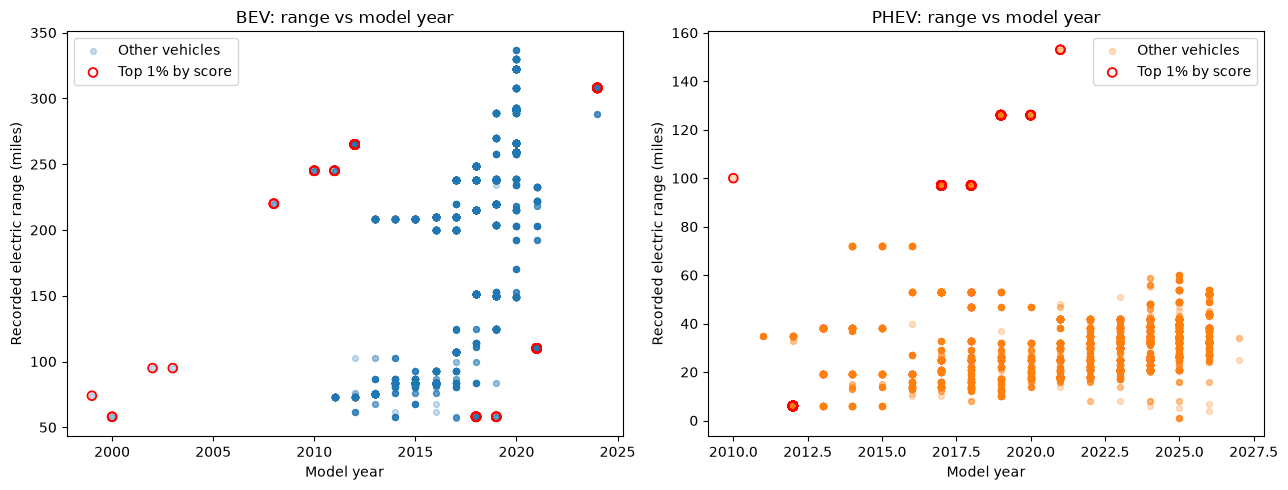

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for a, ev_type, color in zip(ax, ["BEV", "PHEV"], ["tab:blue", "tab:orange"]):
    d = scored[scored["EV_Type"] == ev_type]
    f = d[d["top_flag"]]
    a.scatter(d["Model Year"], d["Electric Range Usable"], s=18, alpha=0.25, color=color, label="Other vehicles")
    a.scatter(f["Model Year"], f["Electric Range Usable"], s=40, facecolors="none", edgecolors="red", linewidths=1.3, label="Top 1% by score")
    a.set_title(ev_type + ": range vs model year")
    a.set_xlabel("Model year")
    a.set_ylabel("Recorded electric range (miles)")
    a.legend()
plt.tight_layout()
plt.show()

## 3.2 Compare with the earlier IQR check

The IQR rule looks at range only, for each EV type. Isolation Forest looks at model year and range together, so the two can disagree.

In [49]:
rows = []
for ev_type in ["BEV", "PHEV"]:
    d = scored[scored["EV_Type"] == ev_type]
    q1, q3 = d["Electric Range Usable"].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    iqr = (d["Electric Range Usable"] < low) | (d["Electric Range Usable"] > high)
    rows.append({
        "EV_Type": ev_type,
        "IQR_lower_fence": low, "IQR_upper_fence": high,
        "IQR_flags": int(iqr.sum()),
        "IsolationForest_flags": int(d["top_flag"].sum()),
        "Flagged_by_both": int((iqr & d["top_flag"]).sum()),
        "IsolationForest_only": int((~iqr & d["top_flag"]).sum()),
        "IQR_only": int((iqr & ~d["top_flag"]).sum()),
    })
print(pd.DataFrame(rows).set_index("EV_Type").T.to_string())

phev = scored[scored["EV_Type"] == "PHEV"]
print()
print("PHEV IQR flags by model:")
q1, q3 = phev["Electric Range Usable"].quantile([0.25, 0.75])
print(phev[phev["Electric Range Usable"] > q3 + 1.5 * (q3 - q1)].groupby(["Make", "Model"]).size().to_string())

glc = phev[(phev["Make"] == "MERCEDES-BENZ") & (phev["Model"] == "GLC-CLASS") & (phev["Electric Range Usable"] <= 1)]
print()
print("Mercedes GLC-Class vehicles with a 1-mile range:", len(glc),
      "| score rank:", int(glc["score_rank"].min()), "of", len(phev),
      "| flagged:", bool(glc["top_flag"].any()))

EV_Type                  BEV   PHEV
IQR_lower_fence         18.0   -2.0
IQR_upper_fence        370.0   62.0
IQR_flags                0.0  174.0
IsolationForest_flags   77.0  149.0
Flagged_by_both          0.0   85.0
IsolationForest_only    77.0   64.0
IQR_only                 0.0   89.0

PHEV IQR flags by model:
Make                  Model 
BMW                   I3        173
WHEEGO ELECTRIC CARS  WHEEGO      1

Mercedes GLC-Class vehicles with a 1-mile range: 4 | score rank: 241 of 9698 | flagged: False


## 3.3 How stable are the flags?

We refit each model with 20 other random seeds and compare the flagged group with the seed-42 group using the Jaccard overlap (1.0 means identical). We also count how often each vehicle is flagged, so we can pick out a robust core.

In [50]:
other_seeds = range(20)
rows, core_tables = [], {}
for ev_type in ["BEV", "PHEV"]:
    d = scored[scored["EV_Type"] == ev_type]
    n_target = int(round(TOP_SHARE * len(d)))
    base = set(d.index[d["top_flag"]])
    jaccards, counts = [], pd.Series(0, index=d.index)
    for s in other_seeds:
        m = IsolationForest(random_state=s, **PARAMS).fit(d[features])
        sc = -m.score_samples(d[features])
        cut = np.sort(sc)[::-1][n_target - 1]
        chosen = set(d.index[sc >= cut])
        jaccards.append(len(chosen & base) / len(chosen | base))
        counts.loc[list(chosen)] += 1
    share = counts / len(other_seeds)
    d2 = d.assign(share_of_seeds_flagged=share)
    core_tables[ev_type] = d2
    rows.append({
        "EV_Type": ev_type,
        "Lowest_overlap": round(min(jaccards), 3),
        "Average_overlap": round(float(np.mean(jaccards)), 3),
        "Flagged_in_90pct_of_seeds": int((share >= 0.9).sum()),
        "Seed42_flags_also_in_90pct": int(((share >= 0.9) & d["top_flag"]).sum()),
    })
print("Agreement with the seed-42 result across 20 other seeds (1.0 = identical):")
print(pd.DataFrame(rows).set_index("EV_Type").T.to_string())

stable = pd.concat(core_tables.values())
core = stable[stable["share_of_seeds_flagged"] >= 0.9]
print()
print("Robust core (flagged in at least 90% of seeds), by model:")
print(core.groupby(["EV_Type", "Make", "Model"]).size().sort_values(ascending=False).to_string())

Agreement with the seed-42 result across 20 other seeds (1.0 = identical):
EV_Type                        BEV    PHEV
Lowest_overlap               0.380   0.467
Average_overlap              0.783   0.667
Flagged_in_90pct_of_seeds   63.000  85.000
Seed42_flags_also_in_90pct  63.000  85.000

Robust core (flagged in at least 90% of seeds), by model:
EV_Type  Make                  Model   
PHEV     BMW                   I3          84
BEV      TESLA                 MODEL S     18
         MINI                  HARDTOP     16
         TESLA                 ROADSTER    13
         PORSCHE               MACAN       11
         FORD                  RANGER       3
         TOYOTA                RAV4         2
PHEV     WHEEGO ELECTRIC CARS  WHEEGO       1


## 3.4 Save the results

In [51]:
out = Path("data/processed/mining")
out.mkdir(parents=True, exist_ok=True)

cols = ["DOL Vehicle ID", "Make", "Model", "EV_Type", "Model Year", "Electric Range Usable",
        "anomaly_score", "score_rank", "top_flag"]
stable_out = stable[cols + ["share_of_seeds_flagged"]].sort_values(["EV_Type", "score_rank"])
stable_out.to_csv(out / "isolation_forest_scores.csv", index=False)
stable_out[stable_out["top_flag"]].to_csv(out / "isolation_forest_top1pct.csv", index=False)

print("Saved", len(stable_out), "scored vehicles to", out / "isolation_forest_scores.csv")
print("Saved", int(stable_out["top_flag"].sum()), "flagged vehicles to", out / "isolation_forest_top1pct.csv")

Saved 17202 scored vehicles to data\processed\mining\isolation_forest_scores.csv
Saved 226 flagged vehicles to data\processed\mining\isolation_forest_top1pct.csv


## 3.5 Summary: Isolation Forest anomaly detection

### What we did
We looked for vehicles with an unusual combination of model year and electric range. We used only the vehicles that have a positive recorded range: 7,504 BEVs and 9,698 PHEVs. Each type got its own Isolation Forest with 200 trees, `max_samples=256`, `contamination="auto"` and a fixed seed of 42. The features stayed in their original units. We reviewed the top 1% of vehicles by anomaly score.

### How we picked the flagged group
- The top 1% is 75 BEVs and 97 PHEVs. Many vehicles share exactly the same year and range, so they get the same score, and the cutoff fell inside such a group for both types.
- Ranking would have flagged only some identical vehicles (for example 12 of 64 identical 2012 Priuses). We flagged every vehicle at or above the cutoff score instead. That gives **77 BEVs (1.03%)** and **149 PHEVs (1.54%)**.
- The model's own `contamination="auto"` threshold flags 2,756 BEVs and 3,159 PHEVs, far too many for a review list, so we did not use it.

### What was flagged
- **BEVs (77):** Tesla Model S 2012 (18), Mini Hardtop 2021 (16), Tesla Roadster 2008 to 2011 (13), Smart EQ Fortwo 2018 and 2019 (14), Porsche Macan 2024 (11), Ford Ranger 1999 and 2000 (3) and Toyota RAV4 2002 and 2003 (2). These are early electric vehicles, a few rare models, and the only recent BEV with a recorded range.
- **PHEVs (149):** BMW i3 range-extenders with 97, 126 or 153 miles (84), one Wheego (100 miles, 2010) and the 2012 Toyota Prius with 6 miles (64).
- All of these are real vehicles that are rare for their type and year. None look like data errors.

### Comparison with the IQR check
- For BEVs, the IQR rule flagged nothing, so Isolation Forest adds information because it uses model year as well as range.
- For PHEVs, the IQR rule flagged 174 vehicles (173 BMW i3 and the Wheego). 85 of them are also flagged here. The other 89 are i3s with 72 miles, a range that other PHEVs of the same years also have, so that combination is not unusual.
- The four Mercedes GLC-Class vehicles with a 1-mile range, our best data-error suspects, rank 241 of 9,698 and are not flagged. Their range is odd, but the 2025 PHEV group has many different ranges, so the combination is not isolated. They should be checked by hand.

### Is it stable?
We refit each model with 20 other seeds. The overlap with the seed-42 flagged group (Jaccard, 1.0 = identical) was 0.380 at the lowest and 0.783 on average for BEVs, and 0.467 and 0.667 for PHEVs. So the exact list changes with the seed, because many vehicles score almost the same near the cutoff. A robust core of **63 BEVs and 85 PHEVs** was flagged in at least 90% of the seeds. Every one of them is also in the seed-42 list. The BEV core is Tesla Model S 2012, Mini Hardtop 2021, Tesla Roadster, Porsche Macan 2024, Ford Ranger and Toyota RAV4. The PHEV core is the BMW i3 and the Wheego. The flags that move around are the Smart EQ Fortwo and the 2012 Prius.

### Limits
- We have no verified labels for errors, so we cannot measure accuracy. A flag means rare, not wrong.
- Only two features are used, so the model finds rare model, year and range combinations. It tends to flag a whole rare model, not single bad records.
- Only vehicles with a positive range are included (18.7% of BEVs), so recent BEVs are mostly missing. This is why a single 2024 Porsche Macan group stands out.
- The 1% share is a review budget, not an estimate of the error rate.
- These are patterns in a sample. They do not explain why a vehicle is unusual.
